# 03 · Selección de modelos y evaluación predictiva

Este cuaderno compara el modelo completo con modelos reducidos de hasta cuatro variables fuente. La selección se realiza exhaustivamente y la evaluación predictiva se mantiene separada de la inferencia.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")


In [2]:
from src.data import load_raw_data, clean_data
from src.config import PREDICTORS
from src.selection import exhaustive_model_search, rank_by_llr_pvalue, rank_by_pseudo_r2, parse_predictor_string
from src.modeling import fit_logit, coefficient_table, model_metrics, evaluate_holdout

clean, _ = clean_data(load_raw_data())

## Búsqueda exhaustiva

Con 13 predictores originales, todas las combinaciones de 1 a 4 variables producen 1,092 candidatos. Las variables categóricas cuentan como una variable fuente aunque internamente se expandan a varias columnas dummy.

In [3]:
search = exhaustive_model_search(clean, PREDICTORS, max_predictors=4)
print(f"Modelos ajustados: {len(search):,}")

by_llr = rank_by_llr_pvalue(search)
by_r2 = rank_by_pseudo_r2(search)

display(by_llr.head(10))

Modelos ajustados: 1,092


,predictors,n_source_predictors,n_parameters,pseudo_r2_mcfadden,log_likelihood,ll_null,llr,llr_p_value,aic,bic
0,cp + oldpeak + ca + thal,4,9,0.4478,-114.9716,-208.2099,186.4766,0.0000,247.9432,281.3370
1,cp + slope + ca + thal,4,10,0.4453,-115.4916,-208.2099,185.4364,0.0000,250.9833,288.0875
2,cp + thalach + ca + thal,4,9,0.4294,-118.8022,-208.2099,178.8154,0.0000,255.6043,288.9982
3,cp + exang + ca + thal,4,9,0.4275,-119.1903,-208.2099,178.0392,0.0000,256.3805,289.7744
4,exang + oldpeak + ca + thal,4,7,0.4107,-122.6904,-208.2099,171.0389,0.0000,259.3808,285.3538
5,sex + cp + slope + ca,4,8,0.4155,-121.7040,-208.2099,173.0118,0.0000,259.4079,289.0913
6,sex + cp + oldpeak + ca,4,7,0.4064,-123.5956,-208.2099,169.2286,0.0000,261.1911,287.1641
7,thalach + exang + ca + thal,4,7,0.4029,-124.3307,-208.2099,167.7584,0.0000,262.6613,288.6343
8,exang + slope + ca + thal,4,8,0.4097,-122.8987,-208.2099,170.6223,0.0000,261.7974,291.4808
9,cp + exang + oldpeak + ca,4,7,0.3971,-125.5377,-208.2099,165.3444,0.0000,265.0753,291.0483


## Mejor modelo por LLR p-value

In [4]:
best_llr = by_llr.iloc[0]
display(best_llr.to_frame("value"))

,value
predictors,cp + oldpeak + ca + thal
n_source_predictors,4
n_parameters,9
pseudo_r2_mcfadden,0.4478
log_likelihood,-114.9716
ll_null,-208.2099
llr,186.4766
llr_p_value,0.0000
aic,247.9432
bic,281.3370


## Mejor modelo por pseudo-R²

In [5]:
best_r2 = by_r2.iloc[0]
display(best_r2.to_frame("value"))

print("Coinciden los criterios:", best_llr["predictors"] == best_r2["predictors"])

,value
predictors,cp + oldpeak + ca + thal
n_source_predictors,4
n_parameters,9
pseudo_r2_mcfadden,0.4478
log_likelihood,-114.9716
ll_null,-208.2099
llr,186.4766
llr_p_value,0.0000
aic,247.9432
bic,281.3370


Coinciden los criterios: True


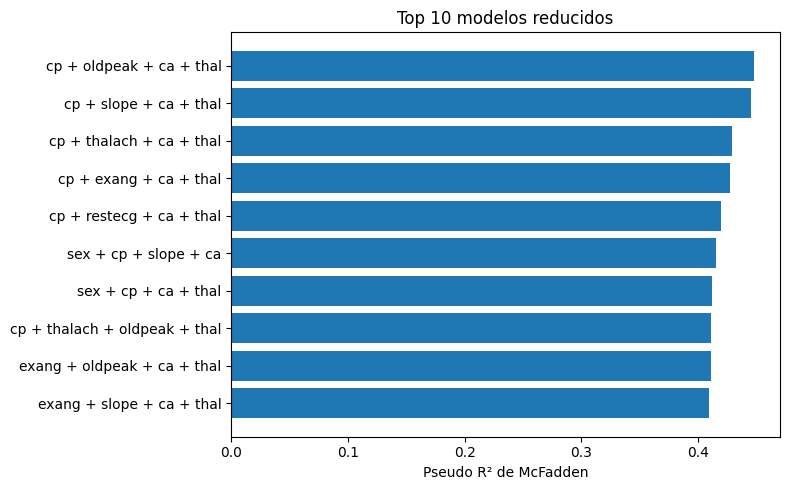

In [6]:
top = by_r2.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8,5))
ax.barh(top["predictors"], top["pseudo_r2_mcfadden"])
ax.set_xlabel("Pseudo R² de McFadden")
ax.set_title("Top 10 modelos reducidos")
plt.tight_layout()
plt.show()

## Coeficientes del modelo reducido seleccionado

In [7]:
best_predictors = parse_predictor_string(best_r2["predictors"])
reduced_model = fit_logit(clean, best_predictors)
display(coefficient_table(reduced_model))
display(model_metrics(reduced_model))

,term,coef,std_err,z,p_value,ci_95_low,ci_95_high,odds_ratio,or_ci_95_low,or_ci_95_high,significant_0_05
0,Intercept,-0.6796,1.8098,-0.3755,0.7073,-4.2267,2.8675,0.5068,0.0146,17.5923,False
1,C(cp)[T.1],1.4628,0.4947,2.9570,0.0031,0.4932,2.4323,4.3179,1.6375,11.3854,True
2,C(cp)[T.2],2.1193,0.4147,5.1111,0.0000,1.3066,2.9320,8.3257,3.6937,18.7660,True
3,C(cp)[T.3],1.9467,0.5891,3.3044,0.0010,0.7920,3.1014,7.0056,2.2079,22.2285,True
4,C(thal)[T.1],0.9881,1.9200,0.5146,0.6068,-2.7750,4.7512,2.6860,0.0623,115.7190,False
5,C(thal)[T.2],2.0438,1.8232,1.1210,0.2623,-1.5296,5.6172,7.7198,0.2166,275.1217,False
6,C(thal)[T.3],0.1025,1.8247,0.0562,0.9552,-3.4738,3.6788,1.1079,0.0310,39.5982,False
7,oldpeak,-0.7601,0.1882,-4.0392,0.0001,-1.1290,-0.3913,0.4676,0.3234,0.6762,True
8,ca,-0.8608,0.1866,-4.6143,0.0000,-1.2264,-0.4952,0.4228,0.2933,0.6095,True


,metric,value
0,nobs,302.0000
1,df_model,8.0000
2,df_resid,293.0000
3,pseudo_r2_mcfadden,0.4478
4,log_likelihood,-114.9716
5,ll_null,-208.2099
6,llr,186.4766
7,llr_p_value,0.0000
8,aic,247.9432
9,bic,281.3370


## Evaluación fuera de muestra

La matriz de confusión y las métricas se calculan en un holdout estratificado del 20%. El modelo predictivo usa el mismo conjunto de variables fuente, con One-Hot Encoding y escalado donde corresponde.

In [8]:
_, cm_full, metrics_full, holdout_full = evaluate_holdout(clean, PREDICTORS)
_, cm_reduced, metrics_reduced, holdout_reduced = evaluate_holdout(clean, best_predictors)

comparison = pd.DataFrame([metrics_full, metrics_reduced], index=["full", "reduced"])
display(comparison)
print("Confusion matrix · full")
print(cm_full)
print("Confusion matrix · reduced")
print(cm_reduced)

,accuracy,precision,recall,f1,roc_auc,n_train,n_test,threshold
full,0.8852,0.8611,0.9394,0.8986,0.9383,241,61,0.5000
reduced,0.8361,0.8108,0.9091,0.8571,0.9096,241,61,0.5000


Confusion matrix · full
[[23  5]
 [ 2 31]]
Confusion matrix · reduced
[[21  7]
 [ 3 30]]


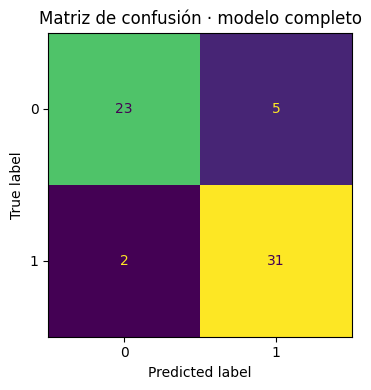

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

fig, ax = plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay(cm_full, display_labels=["0","1"]).plot(ax=ax, colorbar=False)
ax.set_title("Matriz de confusión · modelo completo")
plt.tight_layout()
plt.show()

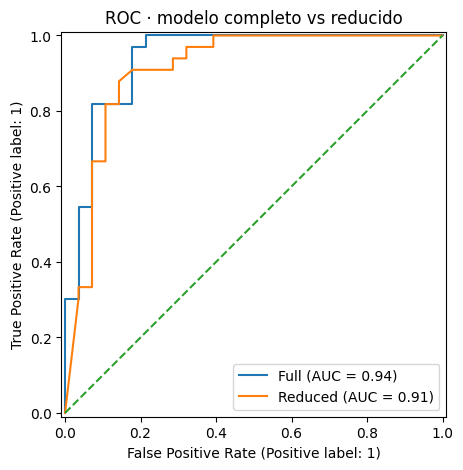

In [10]:
fig, ax = plt.subplots(figsize=(6,5))
RocCurveDisplay.from_predictions(holdout_full[3], holdout_full[4], ax=ax, name="Full")
RocCurveDisplay.from_predictions(holdout_reduced[3], holdout_reduced[4], ax=ax, name="Reduced")
ax.plot([0,1],[0,1], linestyle="--")
ax.set_title("ROC · modelo completo vs reducido")
plt.show()

## Curva logística + dispersión

Una regresión logística multivariable no puede dibujarse completamente como una sola sigmoide 2D. Para visualizar el mecanismo se usa `oldpeak`, que además forma parte del mejor modelo reducido, en un ajuste logístico univariado complementario.

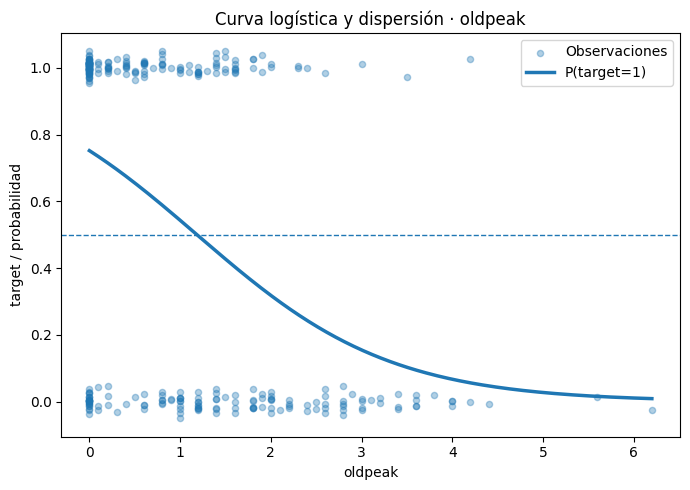

In [11]:
import statsmodels.formula.api as smf

uni = smf.logit("target ~ oldpeak", data=clean).fit(disp=False)
x_grid = np.linspace(clean.oldpeak.min(), clean.oldpeak.max(), 250)
pred = uni.predict(pd.DataFrame({"oldpeak": x_grid}))
rng = np.random.default_rng(2026)
y_jitter = np.clip(clean.target + rng.normal(0, .018, len(clean)), -.05, 1.05)

fig, ax = plt.subplots(figsize=(7,5))
ax.scatter(clean.oldpeak, y_jitter, alpha=.35, s=20, label="Observaciones")
ax.plot(x_grid, pred, linewidth=2.5, label="P(target=1)")
ax.axhline(.5, linestyle="--", linewidth=1)
ax.set_xlabel("oldpeak")
ax.set_ylabel("target / probabilidad")
ax.set_title("Curva logística y dispersión · oldpeak")
ax.legend()
plt.tight_layout()
plt.show()

## Conclusión

Los criterios de LLR p-value y pseudo-R² convergen en `cp + oldpeak + ca + thal`. El modelo completo conserva mejor desempeño predictivo en el holdout, pero el modelo reducido mantiene una discriminación sólida con una especificación mucho más compacta. Esta comparación muestra el trade-off entre parsimonia e información disponible.